<a href="https://colab.research.google.com/github/himanshuzilpe6-ops/MDM_Tasks_EE536/blob/main/Car_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Load the dataset

In [2]:
# Upload `car data.csv` from your computer when running in Colab.
uploaded = files.upload()
csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
if csv_name is None:
    raise FileNotFoundError("Please upload the car data CSV file.")
car_dataset = pd.read_csv(csv_name)
car_dataset.head()


Saving car data.csv to car data.csv


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
print("Dataset shape:", car_dataset.shape)
car_dataset.info()
display(car_dataset.isnull().sum())
display(car_dataset.describe(include="all"))


Dataset shape: (301, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


## 3. Explore the data

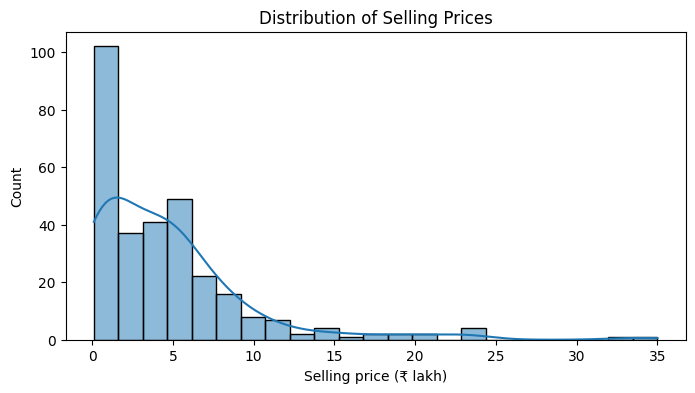

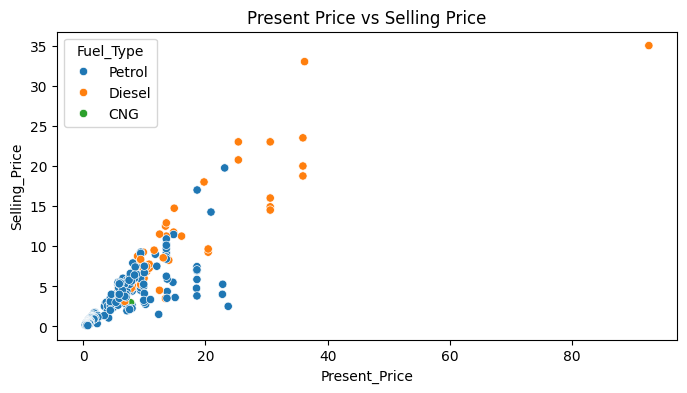

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(car_dataset["Selling_Price"], kde=True)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling price (₹ lakh)")
plt.show()

plt.figure(figsize=(8, 4))
sns.scatterplot(data=car_dataset, x="Present_Price", y="Selling_Price", hue="Fuel_Type")
plt.title("Present Price vs Selling Price")
plt.show()


## 4. Prepare the data

The supplied CSV contains both cars and two-wheelers. To keep this project focused on car resale prices, the preparation step removes known motorcycle and scooter entries before training. The remaining data includes car name/model, year, showroom price, kilometres driven, fuel type, seller type, transmission, and previous owners. Categorical values are one-hot encoded rather than converted into arbitrary numeric codes.

**Note:** The CSV has a `Car_Name` column, which stores model names, not a separate manufacturer `Brand` column. The UI therefore shows car models from the filtered car-only dataset.


In [5]:
# Clean missing values and standardize text columns.
car_dataset = car_dataset.dropna().copy()

required_columns = [
    "Car_Name", "Year", "Selling_Price", "Present_Price", "Kms_Driven",
    "Fuel_Type", "Seller_Type", "Transmission", "Owner"
]
missing_columns = [column for column in required_columns if column not in car_dataset.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

for column in ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]:
    car_dataset[column] = car_dataset[column].astype(str).str.strip()

# This dataset mixes cars and two-wheelers. Remove known bike/scooter entries so
# the model and the dropdown are restricted to cars only.
two_wheeler_names = {
    "Royal Enfield Thunder 500", "UM Renegade Mojave", "KTM RC200",
    "Bajaj Dominar 400", "Royal Enfield Classic 350", "KTM RC390",
    "Hyosung GT250R", "Royal Enfield Thunder 350", "KTM 390 Duke",
    "Mahindra Mojo XT300", "Bajaj Pulsar RS200", "Royal Enfield Bullet 350",
    "Royal Enfield Classic 500", "Bajaj Avenger 220", "Bajaj Avenger 150",
    "Honda CB Hornet 160R", "Yamaha FZ S V 2.0", "Yamaha FZ 16",
    "TVS Apache RTR 160", "Bajaj Pulsar 150", "Honda CBR 150",
    "Hero Extreme", "Bajaj Avenger 220 dtsi", "Bajaj Avenger 150 street",
    "Bajaj Avenger Street 220",
    "Yamaha FZ v 2.0", "Bajaj Pulsar NS 200", "Bajaj Pulsar 220 F",
    "TVS Apache RTR 180", "Hero Passion X pro", "Yamaha Fazer",
    "Honda Activa 4G", "TVS Sport", "Honda Dream Yuga", "Activa 3g",
    "Hero Passion Pro", "Hero Splender iSmart", "Honda CB Trigger", "Yamaha FZ S",
    "Bajaj Pulsar 135 LS", "Activa 4g", "Honda CB Unicorn",
    "Hero Honda CBZ extreme", "Honda Karizma", "Honda Activa 125",
    "TVS Jupyter", "Hero Honda Passion Pro", "Hero Splender Plus",
    "Honda CB Shine", "Bajaj Discover 100", "Suzuki Access 125",
    "TVS Wego", "Honda CB twister", "Hero Glamour", "Hero Super Splendor",
    "Bajaj Discover 125", "Hero Hunk", "Hero Ignitor Disc", "Hero CBZ Xtreme",
    "Bajaj ct 100"
}
# Normalize whitespace/case for reliable matching.
_normalize_name = lambda value: " ".join(str(value).lower().split())
_two_wheeler_keys = {_normalize_name(name) for name in two_wheeler_names}
car_dataset = car_dataset[
    ~car_dataset["Car_Name"].map(_normalize_name).isin(_two_wheeler_keys)
].copy()

for column in ["Year", "Selling_Price", "Present_Price", "Kms_Driven", "Owner"]:
    car_dataset[column] = pd.to_numeric(car_dataset[column], errors="coerce")

car_dataset = car_dataset.dropna(subset=required_columns).copy()
car_dataset = car_dataset[car_dataset["Selling_Price"] >= 0]
car_dataset = car_dataset[car_dataset["Present_Price"] >= 0]
car_dataset = car_dataset[car_dataset["Kms_Driven"] >= 0]

print("Rows available for modelling:", len(car_dataset))
print("Distinct car models (cars only; bikes/scooters excluded):", car_dataset["Car_Name"].nunique())
display(car_dataset.head())


Rows available for modelling: 200
Distinct car models (cars only; bikes/scooters excluded): 37


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 5. Split features and target

The model uses the car name/model and the available vehicle details as inputs. Bike and scooter rows have already been excluded, so the prediction target is limited to the car records in the dataset. `Selling_Price` is the value the model predicts, and a separate test set is retained for evaluation.


In [6]:
feature_names = [
    "Car_Name", "Year", "Present_Price", "Kms_Driven",
    "Fuel_Type", "Seller_Type", "Transmission", "Owner"
]
categorical_features = ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]
numeric_features = ["Year", "Present_Price", "Kms_Driven", "Owner"]

X = car_dataset[feature_names].copy()
Y = car_dataset["Selling_Price"].copy()

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 160
Testing rows: 40


## 6. Train and evaluate models

The notebook compares tree-based regression models. A preprocessing pipeline one-hot encodes the car name/model and other categorical details, while passing numeric values through unchanged. This avoids treating categories such as Manual/Automatic or Petrol/Diesel as if they were ordered numbers.


In [7]:
def make_pipeline(regressor):
    preprocessing = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
            ("numeric", "passthrough", numeric_features),
        ]
    )
    return Pipeline([
        ("preprocessing", preprocessing),
        ("regressor", regressor),
    ])

models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=2, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = {}
for name, regressor in models.items():
    model = make_pipeline(regressor)
    model.fit(X_train, Y_train)
    test_prediction = model.predict(X_test)
    results[name] = {
        "model": model,
        "R2": r2_score(Y_test, test_prediction),
        "MAE": mean_absolute_error(Y_test, test_prediction),
        "RMSE": np.sqrt(mean_squared_error(Y_test, test_prediction)),
        "predictions": test_prediction,
    }
    print(f"\\n{name}")
    print(f"R²:   {results[name]['R2']:.4f}")
    print(f"MAE:  ₹{results[name]['MAE']:.3f} lakh")
    print(f"RMSE: ₹{results[name]['RMSE']:.3f} lakh")


\nExtra Trees
R²:   0.7966
MAE:  ₹1.184 lakh
RMSE: ₹2.222 lakh
\nRandom Forest
R²:   0.9523
MAE:  ₹0.743 lakh
RMSE: ₹1.076 lakh
\nGradient Boosting
R²:   0.9534
MAE:  ₹0.783 lakh
RMSE: ₹1.063 lakh


,Model,R2,MAE (₹ lakh),RMSE (₹ lakh)
2,Gradient Boosting,0.953434,0.782697,1.063106
1,Random Forest,0.952297,0.743084,1.076000
0,Extra Trees,0.796555,1.183746,2.222104


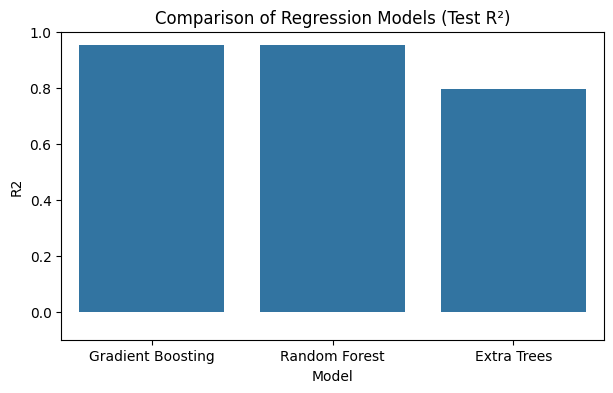

In [8]:
comparison = pd.DataFrame([
    {"Model": name, "R2": result["R2"], "MAE (₹ lakh)": result["MAE"], "RMSE (₹ lakh)": result["RMSE"]}
    for name, result in results.items()
]).sort_values("R2", ascending=False)
display(comparison)

plt.figure(figsize=(7, 4))
sns.barplot(data=comparison, x="Model", y="R2")
plt.title("Comparison of Regression Models (Test R²)")
plt.ylim(min(-0.1, comparison["R2"].min() - 0.1), 1)
plt.show()


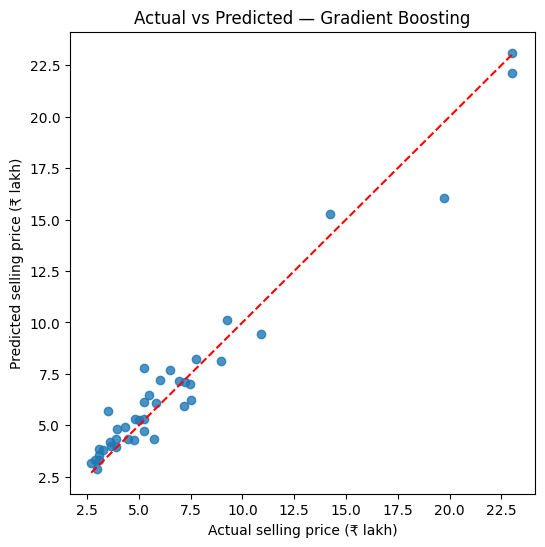

Selected model: Gradient Boosting


In [9]:
best_name = max(results, key=lambda name: results[name]["R2"])
best_model = results[best_name]["model"]
best_predictions = results[best_name]["predictions"]

plt.figure(figsize=(6, 6))
plt.scatter(Y_test, best_predictions, alpha=0.8)
limits = [min(Y_test.min(), best_predictions.min()), max(Y_test.max(), best_predictions.max())]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual selling price (₹ lakh)")
plt.ylabel("Predicted selling price (₹ lakh)")
plt.title(f"Actual vs Predicted — {best_name}")
plt.show()
print("Selected model:", best_name)


## 7. Export model for the local UI

In [10]:
bundle = {
    "model": best_model,
    "model_name": best_name,
    "feature_names": feature_names,
    "car_names": sorted(car_dataset["Car_Name"].unique().tolist()),
    "fuel_types": sorted(car_dataset["Fuel_Type"].unique().tolist()),
    "seller_types": sorted(car_dataset["Seller_Type"].unique().tolist()),
    "transmissions": sorted(car_dataset["Transmission"].unique().tolist()),
    "owners": sorted(car_dataset["Owner"].astype(int).unique().tolist()),
    "metrics": {
        name: {
            "r2": float(result["R2"]),
            "mae": float(result["MAE"]),
            "rmse": float(result["RMSE"])
        } for name, result in results.items()
    },
    "dataset_rows": int(len(car_dataset)),
    "dataset_year_min": int(car_dataset["Year"].min()),
    "dataset_year_max": int(car_dataset["Year"].max())
}
joblib.dump(bundle, "car_price_model.joblib")
print(f"Saved model bundle using {best_name}.")
files.download("car_price_model.joblib")


Saved model bundle using Gradient Boosting.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Launch the car prediction UI in Google Colab

Run this cell after completing the data preparation and model-training cells. The car dropdown is built from the filtered car-only dataset, so bike and scooter names will not appear. Gradio will print a temporary shareable link.


In [ ]:
# Install Gradio if it is not already available in this Colab runtime.
%pip -q install gradio

import gradio as gr
import pandas as pd
import numpy as np

# Build dropdown choices from the actual dataset, not hard-coded categories.
car_name_choices = sorted(car_dataset["Car_Name"].dropna().astype(str).unique().tolist())  # cars only; two-wheelers filtered during preparation
fuel_choices = sorted(car_dataset["Fuel_Type"].dropna().astype(str).unique().tolist())
seller_choices = sorted(car_dataset["Seller_Type"].dropna().astype(str).unique().tolist())
transmission_choices = sorted(car_dataset["Transmission"].dropna().astype(str).unique().tolist())
owner_choices = sorted(car_dataset["Owner"].dropna().astype(int).unique().tolist())

def predict_car_price(car_name, year, present_price, kms_driven, fuel_type, seller_type, transmission, owner):
    try:
        if not car_name:
            return "Please select a car name/model."
        if year is None or present_price is None or kms_driven is None or owner is None:
            return "Please fill in all numeric fields."
        if float(present_price) < 0 or float(kms_driven) < 0:
            return "Present showroom price and kilometres driven cannot be negative."

        input_data = pd.DataFrame([{
            "Car_Name": str(car_name),
            "Year": int(year),
            "Present_Price": float(present_price),
            "Kms_Driven": float(kms_driven),
            "Fuel_Type": str(fuel_type),
            "Seller_Type": str(seller_type),
            "Transmission": str(transmission),
            "Owner": int(owner),
        }], columns=feature_names)

        predicted_price = float(best_model.predict(input_data)[0])
        predicted_price = max(0.0, predicted_price)
        return (
            f"Estimated resale price: ₹{predicted_price:.2f} lakh\\n"
            f"Model used: {best_name}\\n"
            "This is an estimate based on the supplied dataset, not a guaranteed market quote."
        )
    except Exception as error:
        return f"Could not calculate a prediction. Please check the inputs. Details: {error}"

with gr.Blocks(title="Car Resale Price Predictor", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🚗 Car Resale Price Predictor")
    gr.Markdown(
        "Choose a car model and enter its details. Bike and scooter entries have been removed from the dataset. The model uses the car model, manufacturing year, showroom price, kilometres driven, fuel, seller type, transmission, and previous owners. The dataset does not include a separate manufacturer-brand column."
    )

    with gr.Row():
        car_name_input = gr.Dropdown(
            label="Car model",
            choices=car_name_choices,
            value=car_name_choices[0] if car_name_choices else None,
            allow_custom_value=False
        )
        year_input = gr.Slider(
            label="Year of manufacture",
            minimum=int(car_dataset["Year"].min()),
            maximum=int(car_dataset["Year"].max()),
            value=int(car_dataset["Year"].median()),
            step=1
        )

    with gr.Row():
        present_price_input = gr.Number(
            label="Original showroom price (₹ lakh)",
            value=float(car_dataset["Present_Price"].median()),
            minimum=0
        )
        kms_input = gr.Number(
            label="Kilometres driven",
            value=int(car_dataset["Kms_Driven"].median()),
            minimum=0
        )

    with gr.Row():
        fuel_input = gr.Dropdown(
            label="Fuel type", choices=fuel_choices,
            value=fuel_choices[0] if fuel_choices else None
        )
        seller_input = gr.Dropdown(
            label="Seller type", choices=seller_choices,
            value=seller_choices[0] if seller_choices else None
        )

    with gr.Row():
        transmission_input = gr.Dropdown(
            label="Transmission", choices=transmission_choices,
            value=transmission_choices[0] if transmission_choices else None
        )
        owner_input = gr.Dropdown(
            label="Previous owners", choices=owner_choices,
            value=owner_choices[0] if owner_choices else None
        )

    predict_button = gr.Button("Predict resale price", variant="primary")
    result_output = gr.Textbox(label="Prediction", lines=3, interactive=False)

    predict_button.click(
        fn=predict_car_price,
        inputs=[
            car_name_input, year_input, present_price_input, kms_input,
            fuel_input, seller_input, transmission_input, owner_input
        ],
        outputs=result_output
    )

demo.launch(share=True, debug=True)


/tmp/ipykernel_2813/3360230286.py:45: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Car Resale Price Predictor", theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b99c29f3247346f437.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
